# 02. Методология и валидация

Задача — прогнозировать потребление на следующий 15-минутный интервал по уже известным данным. Поэтому при оценке качества сохраняем порядок времени: обучаем модель на прошлом и проверяем её на последующих наблюдениях.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.data_preparation import ROOT, TARGET_COLUMN, load_raw_data
from src.evaluation import RegressionExperiment
from src.features import ALL_FEATURES, LAG_FEATURES, prepare_feature_dataset
from src.pipelines import build_boosting_regressor

feature_dataset = prepare_feature_dataset()
experiment = RegressionExperiment(feature_dataset)
features = experiment.features
target = experiment.target
splits = experiment.splits

## Метрики

В данных есть нулевое и близкое к нулю потребление. При таких значениях MAPE (средняя абсолютная процентная ошибка) либо не определена, либо резко увеличивается из-за малого знаменателя, поэтому мы выбрали основной метрикой MAE (среднюю абсолютную ошибку в кВт·ч). Она позволяет оценить типичную величину отклонения прогноза в единицах потребления. Дополнительно рассчитываем RMSE (корень из средней квадратичной ошибки), чтобы сильнее учитывать крупные ошибки, и R² (коэффициент детерминации), чтобы сопоставить ошибку с вариацией целевой переменной.

## Схема оценки

Нельзя просто перемешать строки и случайно разделить их на обучение и проверку: тогда при обучении может использоваться будущее относительно проверяемого периода. При реальном прогнозировании таких данных ещё нет, поэтому оценка должна сохранять порядок времени.

Для этого применяется временная кросс-валидация:

1. Обучаем модель на раннем участке ряда и проверяем на следующем.
2. Расширяем обучающий участок, добавляя уже прошедшие наблюдения.
3. Заново обучаем модель и проверяем на более позднем участке.

На каждом шаге все обучающие наблюдения предшествуют проверочным. Так можно оценить, как модель работает в разные периоды, не заглядывая в будущее.

Чтобы проверить модель на нескольких последовательных периодах, мы выбрали пять внешних разбиений `TimeSeriesSplit` (разбиение данных с сохранением временного порядка) с расширяющейся обучающей выборкой. Границы разбиений одинаковы для всех моделей и наборов признаков: так различия в результатах не связаны с выбором проверочного периода. Качество описываем средним и выборочным стандартным отклонением метрик по пяти периодам.

Для подбора гиперпараметров каждый внешний обучающий период дополнительно делится на три внутренних временных разбиения. Благодаря этому настройки выбираются без доступа к внешним проверочным значениям.

## Доступность признаков

| Признаки | Доступность к моменту прогноза | Использование |
|---|---|---|
| Календарные признаки | Известны заранее | Включены |
| Лаги 1, 96, 672 | Измерены в завершённых интервалах | Включены при допущении об отсутствии задержки измерений |
| CO₂, реактивные измерения, коэффициенты мощности | Относятся к прогнозируемому интервалу | Исключены |
| `Load_Type` (категория нагрузки) | Доступность заранее не подтверждена | Исключён |

В проверочном периоде лаги обновляются по мере поступления фактических измерений. Такая оценка соответствует последовательному прогнозу на один интервал.

In [2]:
assert feature_dataset.index.is_monotonic_increasing
assert feature_dataset.index.is_unique
assert feature_dataset.index.to_series().diff().dropna().eq(pd.Timedelta("15min")).all()
assert feature_dataset[list(ALL_FEATURES) + [TARGET_COLUMN]].notna().all().all()
raw_data = load_raw_data()
for lag, feature_name in zip([1, 96, 672], LAG_FEATURES):
    expected_lag = raw_data[TARGET_COLUMN].shift(lag).loc[feature_dataset.index]
    np.testing.assert_allclose(feature_dataset[feature_name], expected_lag)
assert "load_type" not in features.columns
print("Проверки временной оси, лагов и набора признаков пройдены")

Проверки временной оси, лагов и набора признаков пройдены


In [3]:
split_boundaries = []
for fold_number, (train_indices, test_indices) in enumerate(splits, 1):
    assert features.index[train_indices[-1]] < features.index[test_indices[0]]
    split_boundaries.append(
        [
            fold_number,
            len(train_indices),
            features.index[train_indices[-1]],
            features.index[test_indices[0]],
            features.index[test_indices[-1]],
            len(test_indices),
        ]
    )
display(
    pd.DataFrame(
        split_boundaries,
        columns=[
            "Фолд",
            "Строк обучения",
            "Конец обучения",
            "Начало проверки",
            "Конец проверки",
            "Строк проверки",
        ],
    )
)

,Фолд,Строк обучения,Конец обучения,Начало проверки,Конец проверки,Строк проверки
0,1,5728,2018-03-08 16:00:00,2018-03-08 16:15:00,2018-05-07 08:00:00,5728
1,2,11456,2018-05-07 08:00:00,2018-05-07 08:15:00,2018-07-06 00:00:00,5728
2,3,17184,2018-07-06 00:00:00,2018-07-06 00:15:00,2018-09-03 16:00:00,5728
3,4,22912,2018-09-03 16:00:00,2018-09-03 16:15:00,2018-11-02 08:00:00,5728
4,5,28640,2018-11-02 08:00:00,2018-11-02 08:15:00,2019-01-01 00:00:00,5728


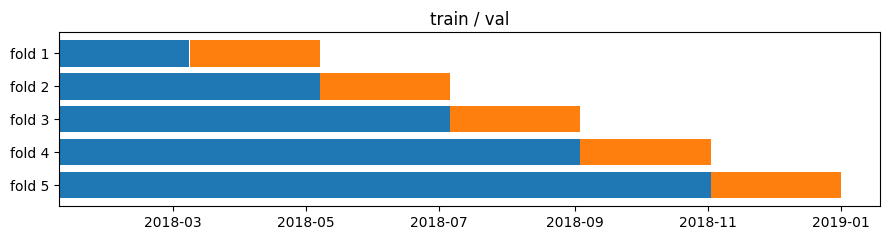

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.5))
for fold_number, (train_indices, validation_indices) in enumerate(splits, start=1):
    train_dates = features.index[train_indices]
    validation_dates = features.index[validation_indices]
    assert train_dates.max() < validation_dates.min()
    ax.barh(
        fold_number,
        train_dates.max() - train_dates.min(),
        left=train_dates.min(),
        color="tab:blue",
    )
    ax.barh(
        fold_number,
        validation_dates.max() - validation_dates.min(),
        left=validation_dates.min(),
        color="tab:orange",
    )
ax.set_yticks(range(1, 6), [f"fold {i}" for i in range(1, 6)])
ax.invert_yaxis()
ax.set_title("train / val")
plt.tight_layout()
plt.show()

## Предобработка и ограничения оценки

Чтобы сведения из проверочного периода не влияли на подготовку признаков, кодирование и масштабирование обучаются внутри `Pipeline` (цепочка предобработки данных и модели) только на обучающей части каждого разбиения. У бустинга отключили `early_stopping` (досрочная остановка обучения), поскольку он использует случайное внутреннее разбиение.

Итоговую модель выбираем по средней MAE внешних разбиений. Отдельную тестовую выборку после этого выбора не выделяли, поэтому для окончательной оценки обобщающей способности потребуются независимые данные.

## Проверка утечки данных

Также проверили, как изменится ошибка, если добавить CO₂ или электрические измерения прогнозируемого интервала. Для этого сравнили такие варианты с моделью на доступных признаках. Этот эксперимент помогает увидеть эффект утечки: в реальном прогнозе будущие измерения ещё неизвестны.

In [5]:
from sklearn.model_selection import cross_validate

power_columns = [
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
]
feature_variants = {
    "Допустимые признаки": features,
    "+ CO2 (утечка)": features.join(raw_data[["CO2(tCO2)"]]),
    "+ измерения интервала (утечка)": features.join(raw_data[power_columns]),
}
rows = []
for variant_name, variant_features in feature_variants.items():
    scores = cross_validate(
        build_boosting_regressor(list(variant_features.columns)),
        variant_features,
        target,
        cv=splits,
        scoring={"MAE": "neg_mean_absolute_error", "R2": "r2"},
        error_score="raise",
    )
    rows.append(
        {
            "Вариант": variant_name,
            "MAE": -scores["test_MAE"].mean(),
            "MAE_std": scores["test_MAE"].std(ddof=1),
            "R2": scores["test_R2"].mean(),
        }
    )
leakage_results = pd.DataFrame(rows)
display(leakage_results.round(3))
(ROOT / "results/tables").mkdir(parents=True, exist_ok=True)
leakage_results.to_csv(ROOT / "results/tables/leakage_diagnostic.csv", index=False)

,Вариант,MAE,MAE_std,R2
0,Допустимые признаки,4.808,0.684,0.903
1,+ CO2 (утечка),1.925,0.123,0.988
2,+ измерения интервала (утечка),0.865,0.138,0.997


Добавление измерений прогнозируемого интервала снижает ошибку, но заранее эти сведения недоступны. Поэтому из основных экспериментов их исключили: полученное с ними качество нельзя ожидать при прогнозировании в выбранных условиях.